In [2]:
import os

path = r"E:\archive\EuroSAT"

for name in os.listdir(path):
    print(name)

AnnualCrop
Forest
HerbaceousVegetation
Highway
Industrial
label_map.json
Pasture
PermanentCrop
Residential
River
SeaLake
test.csv
train.csv
validation.csv


In [3]:

folder = r"E:\archive\EuroSAT\Forest"
files = os.listdir(folder)

print(len(files))
print(files[:5]) 

3000
['Forest_1.jpg', 'Forest_10.jpg', 'Forest_100.jpg', 'Forest_1000.jpg', 'Forest_1001.jpg']


(64, 64, 3)
uint8


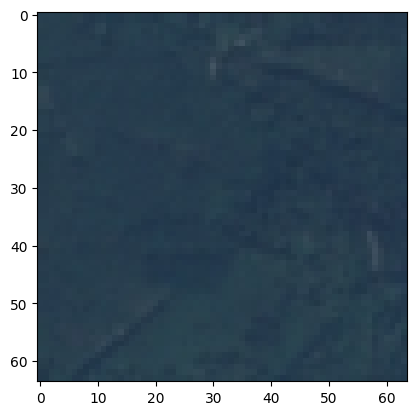

In [4]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

img = Image.open(os.path.join(folder, files[0]))
arr = np.array(img)

print(arr.shape)
print(arr.dtype)

plt.imshow(arr)
plt.show()

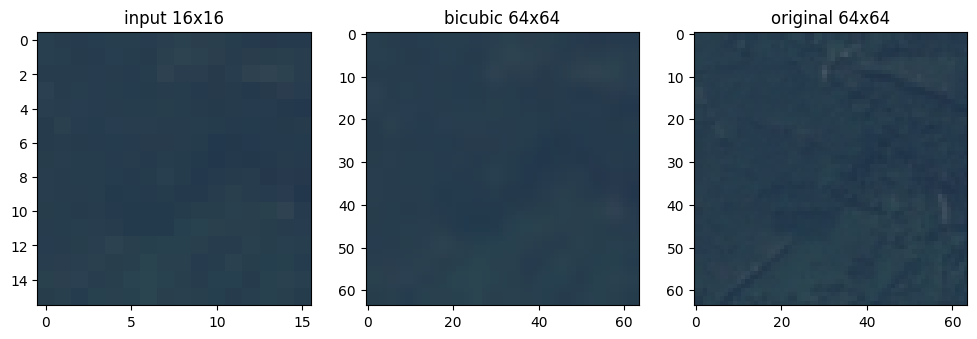

In [5]:
small = img.resize((16, 16), Image.BICUBIC)
blurry = small.resize((64, 64), Image.BICUBIC)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(small);  ax[0].set_title("input 16x16")
ax[1].imshow(blurry); ax[1].set_title("bicubic 64x64")
ax[2].imshow(img);    ax[2].set_title("original 64x64")
plt.show()

In [6]:
a = np.array(blurry).astype(np.float64)
b = np.array(img).astype(np.float64)

diff = a - b
squared = diff ** 2
mse = np.mean(squared)

score = 10 * np.log10(255 * 255 / mse)
print(score)

40.338818658761504


In [6]:
root = r"E:\archive\EuroSAT"
classes = ["Forest", "Residential", "Highway", "River"]

def psnr(a, b):
    a = np.array(a).astype(np.float64)
    b = np.array(b).astype(np.float64)
    mse = np.mean((a - b) ** 2)
    return 10 * np.log10(255 * 255 / mse)

results = {}

for c in classes:
    folder = os.path.join(root, c)
    files = os.listdir(folder)[:50]      # first 50 pictures of this class
    scores = []

    for f in files:
        img = Image.open(os.path.join(folder, f))

        small = img.resize((16, 16), Image.BICUBIC)
        blurry = small.resize((64, 64), Image.BICUBIC)

        scores.append(psnr(blurry, img))

    results[c] = np.mean(scores)
    print(c, results[c])

print("overall:", np.mean(list(results.values())))

Forest 40.20229049606334
Residential 25.681693175401804
Highway 28.413446912010123
River 31.382121725514107
overall: 31.419888077247343


In [13]:
import pandas as pd

train = pd.read_csv(r"E:\archive\EuroSAT\train.csv")
print(train.head())
print(len(train))

   Unnamed: 0                                           Filename  Label  \
0       16257                      AnnualCrop/AnnualCrop_142.jpg      0   
1        3297  HerbaceousVegetation/HerbaceousVegetation_2835...      2   
2       17881               PermanentCrop/PermanentCrop_1073.jpg      6   
3        2223                      Industrial/Industrial_453.jpg      4   
4        4887  HerbaceousVegetation/HerbaceousVegetation_1810...      2   

              ClassName  
0            AnnualCrop  
1  HerbaceousVegetation  
2         PermanentCrop  
3            Industrial  
4  HerbaceousVegetation  
18900


In [14]:
import torch
print(torch.__version__)

2.11.0+cpu


In [4]:
import os
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset

class SRDataset(Dataset):
    def __init__(self, root, csv_name):
        self.root = root
        df = pd.read_csv(os.path.join(root, csv_name))
        self.files = df["Filename"].tolist()

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img = Image.open(os.path.join(self.root, self.files[i]))
        small = img.resize((16, 16), Image.BICUBIC)
        small_arr=np.array(small).astype(np.float32) / 255.0
        img_arr=np.array(img).astype(np.float32) / 255.0
        small_tensor = torch.from_numpy(small_arr).permute(2, 0, 1)
        img_tensor = torch.from_numpy(img_arr).permute(2, 0, 1)

        return small_tensor, img_tensor

In [5]:
ds = SRDataset(r"E:\archive\EuroSAT", "train.csv")
x, y = ds[0]
print(len(ds), x.shape, y.shape)

18900 torch.Size([3, 16, 16]) torch.Size([3, 64, 64])


In [7]:
from torch.utils.data import DataLoader

ds_train = SRDataset(r"E:\archive\EuroSAT", "train.csv")
ds_val   = SRDataset(r"E:\archive\EuroSAT", "validation.csv")

train_loader = DataLoader(ds_train, batch_size=16, shuffle=True)
val_loader   = DataLoader(ds_val, batch_size=16, shuffle=False)

xb, yb = next(iter(train_loader))
print(len(ds_train), len(ds_val))
print(xb.shape, yb.shape)

18900 5400
torch.Size([16, 3, 16, 16]) torch.Size([16, 3, 64, 64])


In [8]:
import torch.nn as nn

class SRNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
        )
        self.up = nn.Sequential(
            nn.Conv2d(64, 3 * 16, 3, padding=1),
            nn.PixelShuffle(4),
        )

    def forward(self, x):
        return self.up(self.body(x))

In [9]:
model = SRNet()
out = model(xb)
print(out.shape)
print(sum(p.numel() for p in model.parameters()))

torch.Size([16, 3, 64, 64])
103344


In [12]:
import torch
import torch.nn as nn

model = SRNet()
loss_fn = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5):
    total = 0
    for i, (xb, yb) in enumerate(train_loader):
        pred = model(xb)
        loss = loss_fn(pred, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item()
        if i % 200 == 0:
            print(i, loss.item())

    print("epoch", epoch, "average loss", total / len(train_loader))

0 0.3832627832889557
200 0.0315367691218853
400 0.021141352131962776
600 0.04476262629032135
800 0.016140369698405266
1000 0.027710096910595894
epoch 0 average loss 0.03090133580856668
0 0.026040518656373024
200 0.025535019114613533
400 0.025238273665308952
600 0.02347571589052677
800 0.02943357266485691
1000 0.02790648676455021
epoch 1 average loss 0.023391149793917
0 0.020729364827275276
200 0.018252931535243988
400 0.016918785870075226
600 0.02807232178747654
800 0.01967383176088333
1000 0.024549834430217743
epoch 2 average loss 0.023110395558209942
0 0.027431895956397057
200 0.022806720808148384
400 0.020976444706320763
600 0.039809729903936386
800 0.019300078973174095
1000 0.023875243961811066
epoch 3 average loss 0.022381794231576616
0 0.025228356942534447
200 0.02464580535888672
400 0.01667124219238758
600 0.019326232373714447
800 0.0233440101146698
1000 0.017906075343489647
epoch 4 average loss 0.022017991852626685


In [21]:
import torch.nn.functional as F
def psnr_batch(a, b):
    mse = ((a - b) ** 2).mean(dim=(1, 2, 3))
    return (10 * torch.log10(1.0 / mse)).mean().item()

model.eval()
model_scores, bicubic_scores = [], []

with torch.no_grad():
    for xb, yb in val_loader:
        pred = model(xb).clamp(0, 1)
        bic = F.interpolate(xb, scale_factor=4, mode="bicubic",
                            align_corners=False).clamp(0, 1)
        model_scores.append(psnr_batch(pred, yb))
        bicubic_scores.append(psnr_batch(bic, yb))

print("model  :", sum(model_scores) / len(model_scores))
print("bicubic:", sum(bicubic_scores) / len(bicubic_scores))

model  : 33.64139620651155
bicubic: 32.63521382371349


In [14]:
torch.save(model.state_dict(), "srnet_v1.pth")

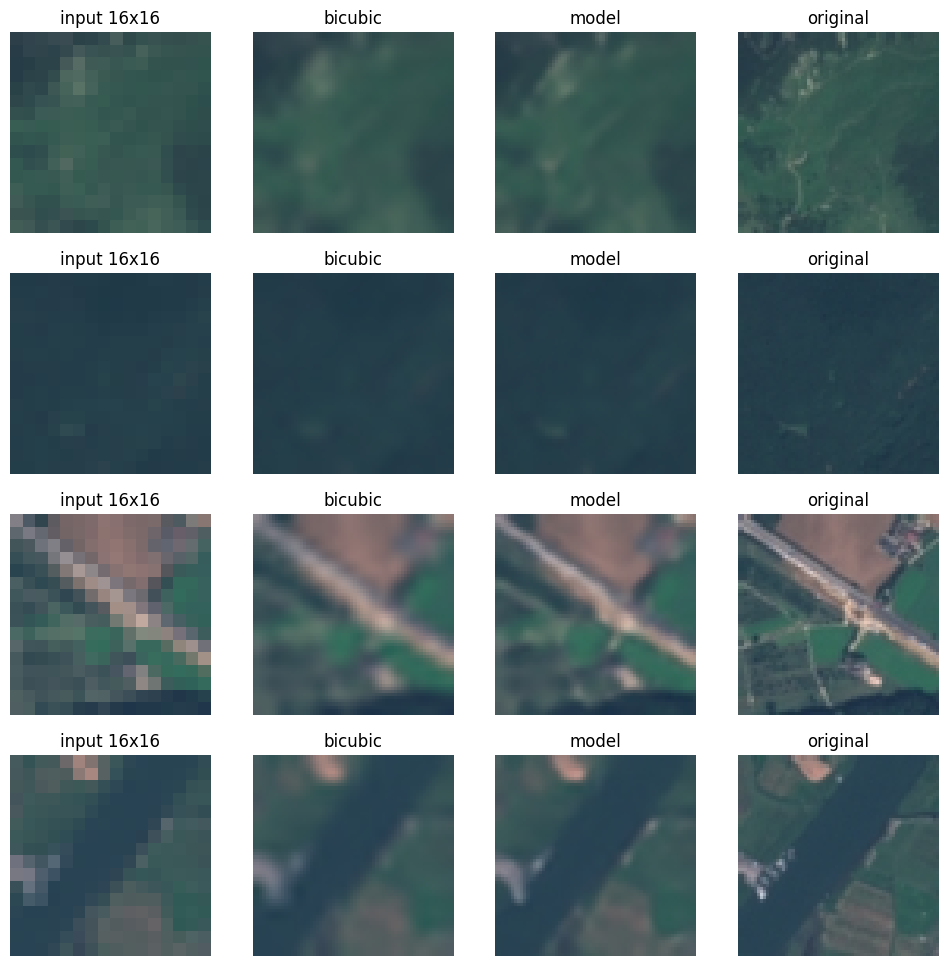

In [23]:
import matplotlib.pyplot as plt

model.eval()
xb, yb = next(iter(val_loader))

with torch.no_grad():
    pred = model(xb).clamp(0, 1)
    bic = F.interpolate(xb, scale_factor=4, mode="bicubic",
                        align_corners=False).clamp(0, 1)

def show(t):
    return t.permute(1, 2, 0).numpy()

fig, ax = plt.subplots(4, 4, figsize=(12, 12))
for r in range(4):
    ax[r, 0].imshow(show(xb[r]));   ax[r, 0].set_title("input 16x16")
    ax[r, 1].imshow(show(bic[r]));  ax[r, 1].set_title("bicubic")
    ax[r, 2].imshow(show(pred[r])); ax[r, 2].set_title("model")
    ax[r, 3].imshow(show(yb[r]));   ax[r, 3].set_title("original")
    for c in range(4):
        ax[r, c].axis("off")
plt.show()

In [20]:
best = 33.39

for epoch in range(10):
    model.train()
    total = 0
    for xb, yb in train_loader:
        pred = model(xb)
        loss = loss_fn(pred, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item()

    model.eval()
    scores = []
    with torch.no_grad():
        for xb, yb in val_loader:
            scores.append(psnr_batch(model(xb).clamp(0, 1), yb))
    val = sum(scores) / len(scores)

    print("epoch", epoch, "train loss", round(total / len(train_loader), 4),
          "val PSNR", round(val, 3))

    if val > best:
        best = val
        torch.save(model.state_dict(), "srnet_best.pth")
        print("  saved best")

epoch 0 train loss 0.0204 val PSNR 33.594
  saved best
epoch 1 train loss 0.0204 val PSNR 33.603
  saved best
epoch 2 train loss 0.0204 val PSNR 33.583
epoch 3 train loss 0.0204 val PSNR 33.608
  saved best
epoch 4 train loss 0.0203 val PSNR 33.622
  saved best
epoch 5 train loss 0.0203 val PSNR 33.618
epoch 6 train loss 0.0203 val PSNR 33.622
  saved best
epoch 7 train loss 0.0203 val PSNR 33.596
epoch 8 train loss 0.0203 val PSNR 33.613
epoch 9 train loss 0.0203 val PSNR 33.641
  saved best


In [19]:
model.load_state_dict(torch.load("srnet_best.pth"))

for g in optimizer.param_groups:
    g["lr"] = 2e-4

In [22]:
torch.save(model.state_dict(), "srnet_v2_final.pth")

In [24]:
class ResBlock(nn.Module):
    def __init__(self, ch=64):
        super().__init__()
        self.conv1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        return x + self.conv2(self.relu(self.conv1(x)))


class SRNet2(nn.Module):
    def __init__(self, ch=64, n_blocks=4):
        super().__init__()
        self.head = nn.Conv2d(3, ch, 3, padding=1)
        self.blocks = nn.Sequential(*[ResBlock(ch) for _ in range(n_blocks)])
        self.up = nn.Sequential(
            nn.Conv2d(ch, 3 * 16, 3, padding=1),
            nn.PixelShuffle(4),
        )

    def forward(self, x):
        base = F.interpolate(x, scale_factor=4, mode="bicubic", align_corners=False)
        feat = self.head(x)
        feat = feat + self.blocks(feat)
        return base + self.up(feat)

In [25]:
model = SRNet2()
print(model(xb).shape)
print(sum(p.numel() for p in model.parameters()))

torch.Size([16, 3, 64, 64])
324912


In [26]:
model = SRNet2()
loss_fn = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)
best = 0.0

for epoch in range(10):
    model.train()
    total = 0
    for xb, yb in train_loader:
        pred = model(xb)
        loss = loss_fn(pred, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item()

    scheduler.step()

    model.eval()
    scores = []
    with torch.no_grad():
        for xb, yb in val_loader:
            scores.append(psnr_batch(model(xb).clamp(0, 1), yb))
    val = sum(scores) / len(scores)

    print("epoch", epoch, "train loss", round(total / len(train_loader), 4),
          "val PSNR", round(val, 3))

    if val > best:
        best = val
        torch.save(model.state_dict(), "srnet2_best.pth")
        print("  saved best")

epoch 0 train loss 0.0228 val PSNR 33.247
  saved best
epoch 1 train loss 0.0209 val PSNR 33.451
  saved best
epoch 2 train loss 0.0205 val PSNR 33.574
  saved best
epoch 3 train loss 0.0203 val PSNR 33.636
  saved best
epoch 4 train loss 0.0202 val PSNR 33.705
  saved best
epoch 5 train loss 0.02 val PSNR 33.739
  saved best
epoch 6 train loss 0.0199 val PSNR 33.822
  saved best
epoch 7 train loss 0.0198 val PSNR 33.861
  saved best
epoch 8 train loss 0.0197 val PSNR 33.896
  saved best
epoch 9 train loss 0.0196 val PSNR 33.912
  saved best


In [27]:
val_df = pd.read_csv(r"E:\archive\EuroSAT\validation.csv")
class_col = val_df["ClassName"].tolist()

def psnr_each(a, b):
    mse = ((a - b) ** 2).mean(dim=(1, 2, 3))
    return 10 * torch.log10(1.0 / mse)

model.eval()
rows, idx = [], 0
with torch.no_grad():
    for xb, yb in val_loader:
        pred = model(xb).clamp(0, 1)
        bic = F.interpolate(xb, scale_factor=4, mode="bicubic",
                            align_corners=False).clamp(0, 1)
        pm, pb = psnr_each(pred, yb), psnr_each(bic, yb)
        for k in range(len(xb)):
            rows.append((class_col[idx], pm[k].item(), pb[k].item()))
            idx += 1

res = pd.DataFrame(rows, columns=["class", "model", "bicubic"])
res["gain"] = res["model"] - res["bicubic"]
print(res.groupby("class").mean().round(2))

                      model  bicubic  gain
class                                     
AnnualCrop            36.24    32.93  3.32
Forest                41.07    40.57  0.50
HerbaceousVegetation  32.83    32.11  0.72
Highway               30.68    28.88  1.80
Industrial            23.41    22.07  1.34
Pasture               36.83    35.57  1.26
PermanentCrop         29.81    28.65  1.16
Residential           25.62    25.12  0.50
River                 33.35    31.45  1.90
SeaLake               47.15    46.73  0.43


In [28]:
from skimage.metrics import structural_similarity as ssim

ds_test = SRDataset(r"E:\archive\EuroSAT", "test.csv")
test_loader = DataLoader(ds_test, batch_size=16, shuffle=False)

model = SRNet2()
model.load_state_dict(torch.load("srnet2_best.pth"))
model.eval()

def to_np(t):
    return t.permute(1, 2, 0).numpy()

psnr_m, psnr_b, ssim_m, ssim_b = [], [], [], []

with torch.no_grad():
    for xb, yb in test_loader:
        pred = model(xb).clamp(0, 1)
        bic = F.interpolate(xb, scale_factor=4, mode="bicubic",
                            align_corners=False).clamp(0, 1)

        psnr_m += psnr_each(pred, yb).tolist()
        psnr_b += psnr_each(bic, yb).tolist()

        for k in range(len(xb)):
            ssim_m.append(ssim(to_np(pred[k]), to_np(yb[k]), channel_axis=2, data_range=1.0))
            ssim_b.append(ssim(to_np(bic[k]),  to_np(yb[k]), channel_axis=2, data_range=1.0))

print("test pictures:", len(ds_test))
print("PSNR  model :", sum(psnr_m) / len(psnr_m))
print("PSNR  bicubic:", sum(psnr_b) / len(psnr_b))
print("SSIM  model :", sum(ssim_m) / len(ssim_m))
print("SSIM  bicubic:", sum(ssim_b) / len(ssim_b))

test pictures: 2700
PSNR  model : 33.93873722570914
PSNR  bicubic: 32.68585276709663
SSIM  model : 0.83119893
SSIM  bicubic: 0.7827248


In [29]:
torch.save(model.state_dict(), "srnet2_final.pth")

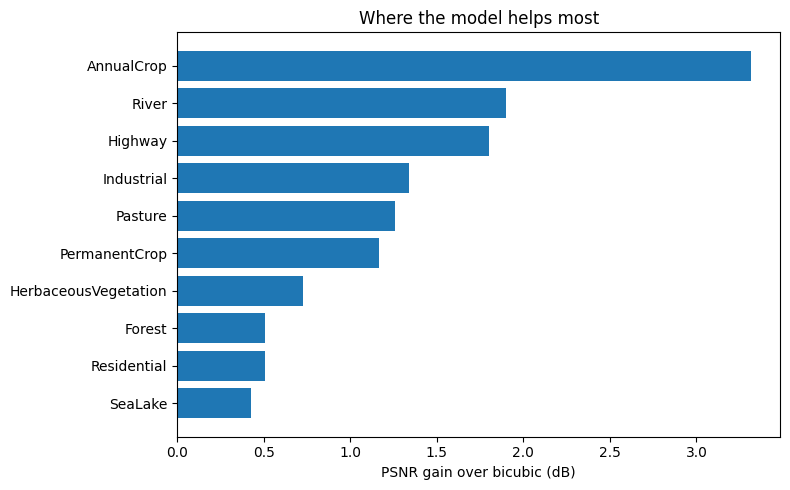

In [30]:
import matplotlib.pyplot as plt

g = res.groupby("class")["gain"].mean().sort_values()

plt.figure(figsize=(8, 5))
plt.barh(g.index, g.values)
plt.xlabel("PSNR gain over bicubic (dB)")
plt.title("Where the model helps most")
plt.tight_layout()
plt.savefig("gain_per_class.png", dpi=150)
plt.show()

In [31]:
plt.savefig("comparison_grid.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [33]:
def test_on_image(path, size=256):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    left, top = (w - size) // 2, (h - size) // 2
    hr = img.crop((left, top, left + size, top + size))   # native pixels
    lr = hr.resize((size // 4, size // 4), Image.BICUBIC)

    x = torch.from_numpy(np.array(lr).astype(np.float32) / 255).permute(2, 0, 1).unsqueeze(0)
    y = torch.from_numpy(np.array(hr).astype(np.float32) / 255).permute(2, 0, 1).unsqueeze(0)

    model.eval()
    with torch.no_grad():
        pred = model(x).clamp(0, 1)
        bic = F.interpolate(x, scale_factor=4, mode="bicubic",
                            align_corners=False).clamp(0, 1)

    print("PSNR model  :", psnr_each(pred, y).item())
    print("PSNR bicubic:", psnr_each(bic, y).item())

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    for a, t, name in zip(ax, [x[0], bic[0], pred[0], y[0]],
                          ["input", "bicubic", "model", "original"]):
        a.imshow(t.permute(1, 2, 0).numpy()); a.set_title(name); a.axis("off")
    plt.show()

In [34]:
model = SRNet2()
model.load_state_dict(torch.load("srnet2_final.pth"))

<All keys matched successfully>

PSNR model  : 33.01115036010742
PSNR bicubic: 32.22816467285156


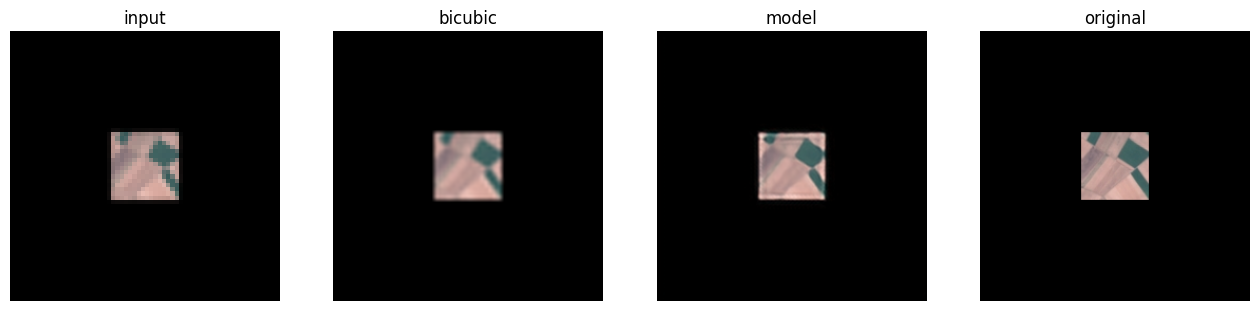

In [36]:
test_on_image(r"E:\archive (1)\EuroSAT_RGB\AnnualCrop\AnnualCrop_3.jpg")

In [37]:
import os
import numpy as np
import torch
from PIL import Image

# load the trained model
model = SRNet2()
model.load_state_dict(torch.load("srnet2_final.pth"))
model.eval()

def upscale_tensor(x, tile=128, pad=8):
    _, c, h, w = x.shape
    out = torch.zeros(1, c, h * 4, w * 4)
    for y in range(0, h, tile):
        for xx in range(0, w, tile):
            y0, x0 = max(y - pad, 0), max(xx - pad, 0)
            y1, x1 = min(y + tile + pad, h), min(xx + tile + pad, w)
            patch = x[:, :, y0:y1, x0:x1]
            with torch.no_grad():
                p = model(patch).clamp(0, 1)
            ty, tx = (y - y0) * 4, (xx - x0) * 4
            th, tw = min(tile, h - y) * 4, min(tile, w - xx) * 4
            out[:, :, y * 4:y * 4 + th, xx * 4:xx * 4 + tw] = p[:, :, ty:ty + th, tx:tx + tw]
    return out

in_root  = r"E:\archive (1)"
out_root = in_root + "_x4"
exts = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

count = 0
for folder, _, files in os.walk(in_root):
    rel = os.path.relpath(folder, in_root)
    out_folder = os.path.join(out_root, rel)
    os.makedirs(out_folder, exist_ok=True)

    for f in files:
        if not f.lower().endswith(exts):
            continue
        img = Image.open(os.path.join(folder, f)).convert("RGB")
        arr = np.array(img).astype(np.float32) / 255.0
        x = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)

        up = upscale_tensor(x)

        out_arr = (up[0].permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
        name = os.path.splitext(f)[0] + ".png"
        Image.fromarray(out_arr).save(os.path.join(out_folder, name))

        count += 1
        print(count, f, img.size, "->", (img.size[0] * 4, img.size[1] * 4))

print("done:", count, "pictures saved in", out_root)

1 AnnualCrop_1.jpg (64, 64) -> (256, 256)
2 AnnualCrop_10.jpg (64, 64) -> (256, 256)
3 AnnualCrop_100.jpg (64, 64) -> (256, 256)
4 AnnualCrop_1000.jpg (64, 64) -> (256, 256)
5 AnnualCrop_1001.jpg (64, 64) -> (256, 256)
6 AnnualCrop_1002.jpg (64, 64) -> (256, 256)
7 AnnualCrop_1003.jpg (64, 64) -> (256, 256)
8 AnnualCrop_1004.jpg (64, 64) -> (256, 256)
9 AnnualCrop_1005.jpg (64, 64) -> (256, 256)
10 AnnualCrop_1006.jpg (64, 64) -> (256, 256)
11 AnnualCrop_1007.jpg (64, 64) -> (256, 256)
12 AnnualCrop_1008.jpg (64, 64) -> (256, 256)
13 AnnualCrop_1009.jpg (64, 64) -> (256, 256)
14 AnnualCrop_101.jpg (64, 64) -> (256, 256)
15 AnnualCrop_1010.jpg (64, 64) -> (256, 256)
16 AnnualCrop_1011.jpg (64, 64) -> (256, 256)
17 AnnualCrop_1012.jpg (64, 64) -> (256, 256)
18 AnnualCrop_1013.jpg (64, 64) -> (256, 256)
19 AnnualCrop_1014.jpg (64, 64) -> (256, 256)
20 AnnualCrop_1015.jpg (64, 64) -> (256, 256)
21 AnnualCrop_1016.jpg (64, 64) -> (256, 256)
22 AnnualCrop_1017.jpg (64, 64) -> (256, 256)
23 A

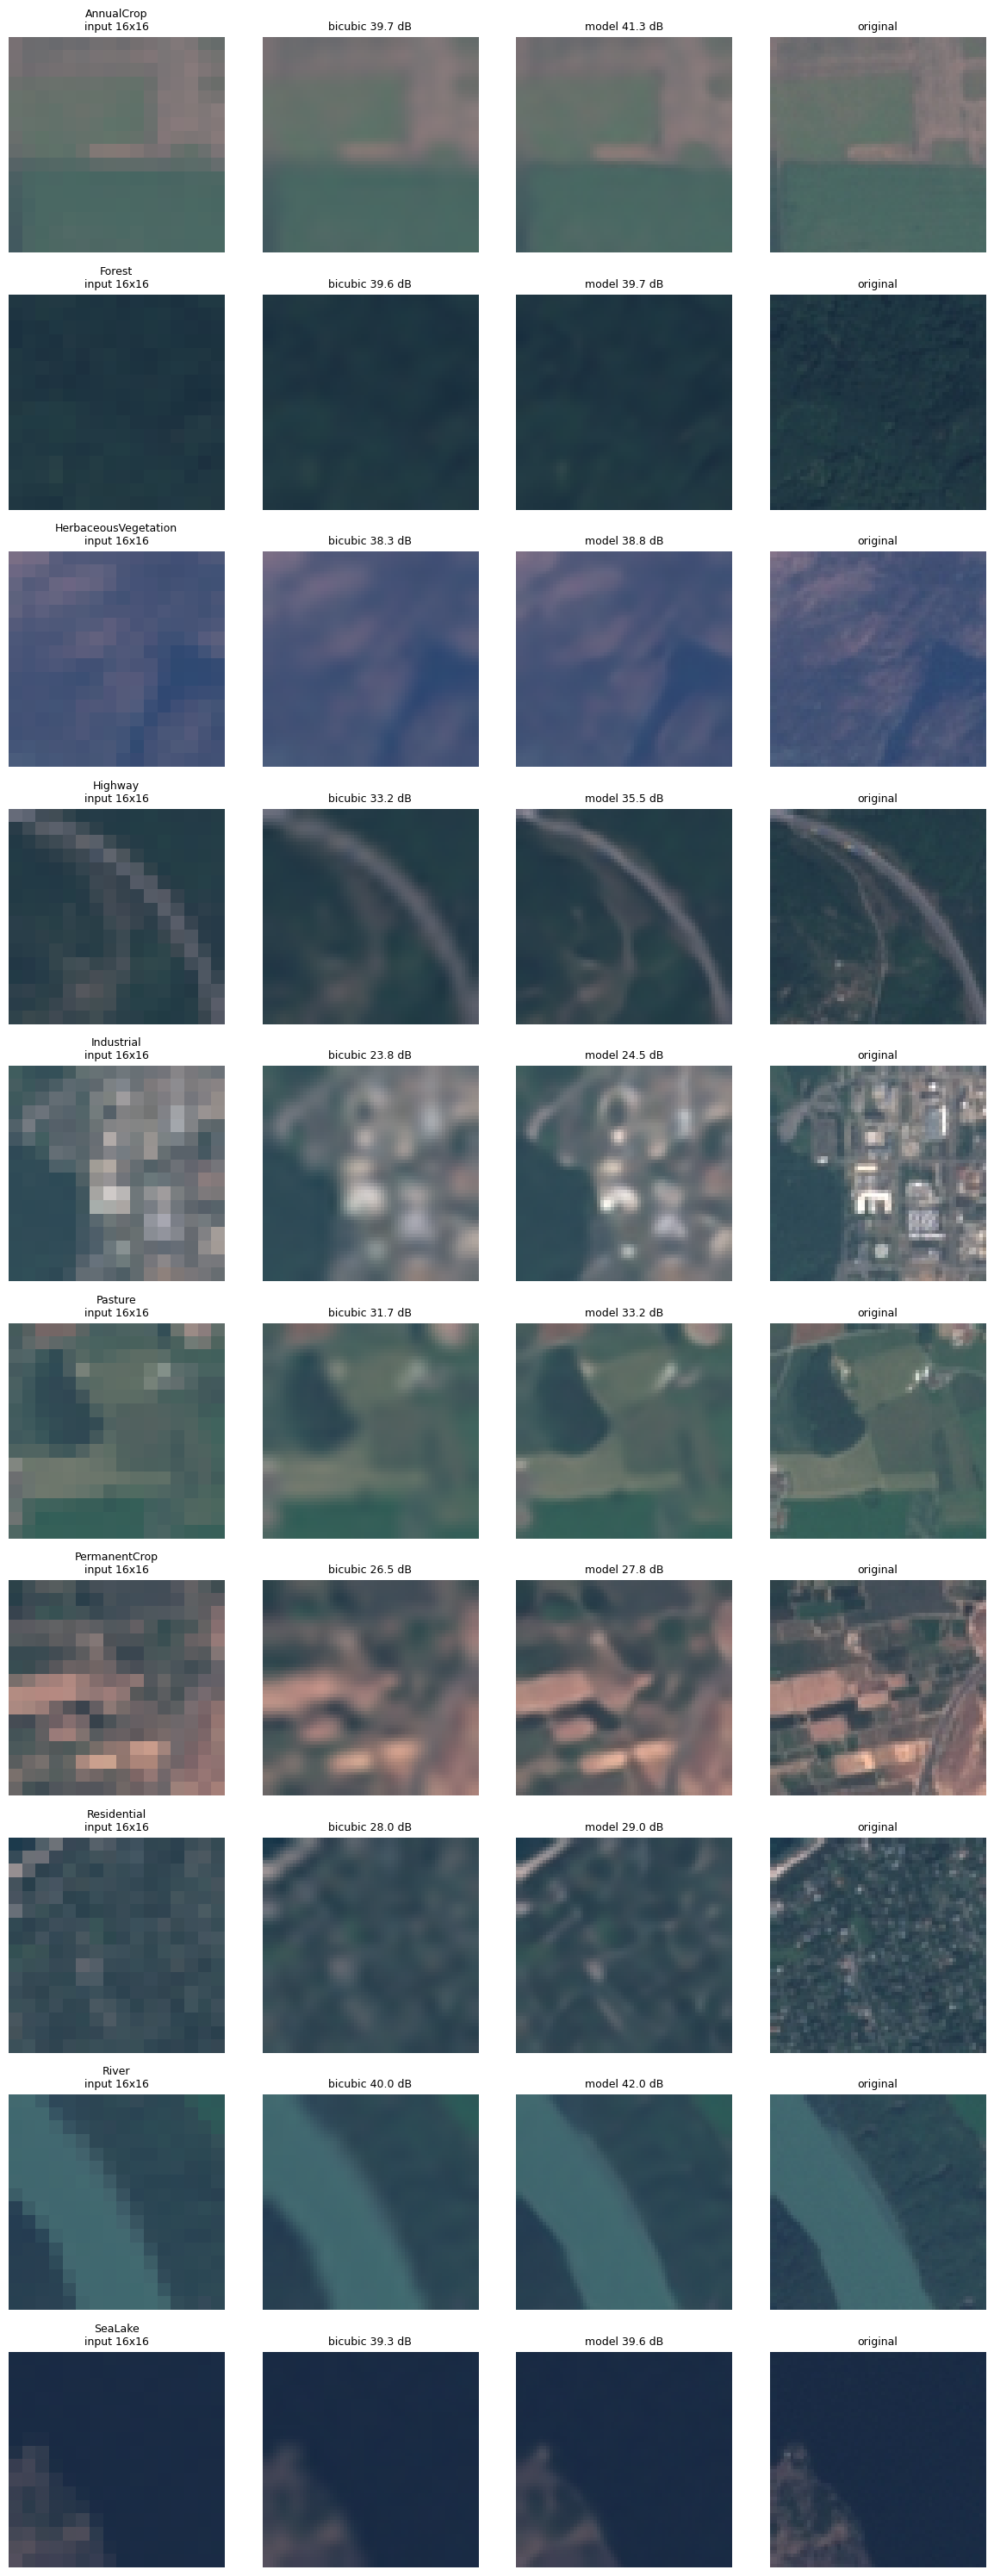

In [38]:
test_df = pd.read_csv(r"E:\archive\EuroSAT\test.csv")
class_names = sorted(test_df["ClassName"].unique())

model.eval()
fig, ax = plt.subplots(len(class_names), 4, figsize=(12, 3 * len(class_names)))

for r, cname in enumerate(class_names):
    i = test_df.index[test_df["ClassName"] == cname][0]   # first test picture of this class
    x, y = ds_test[i]
    x, y = x.unsqueeze(0), y.unsqueeze(0)

    with torch.no_grad():
        pred = model(x).clamp(0, 1)
        bic = F.interpolate(x, scale_factor=4, mode="bicubic",
                            align_corners=False).clamp(0, 1)

    p_m = psnr_each(pred, y).item()
    p_b = psnr_each(bic, y).item()

    panels = [x[0], bic[0], pred[0], y[0]]
    titles = [f"{cname}\ninput 16x16", f"bicubic {p_b:.1f} dB",
              f"model {p_m:.1f} dB", "original"]
    for c in range(4):
        ax[r, c].imshow(panels[c].permute(1, 2, 0).numpy())
        ax[r, c].set_title(titles[c], fontsize=9)
        ax[r, c].axis("off")

plt.tight_layout()
plt.savefig("class_comparison.png", dpi=130, bbox_inches="tight", facecolor="white")
plt.show()